# Checkpoint pipeline — QPINN vs. classical PINN

One notebook for both headline experiments, run from checkpoints so training
never has to be repeated just to change a plot:

1. **Parameter sweep** — fix architecture size `L`, sweep `(freq, alpha)` (heat)
   or `(freq, c)` (wave), classical vs. quantum, heatmap of `rel_l2`.
2. **L sweep** — fix `(freq, alpha)`/`(freq, c)`, sweep `L`, classical vs.
   quantum, line plot of `rel_l2` vs. `L`.

Both experiments share ONE notion of "model size `L`": the quantum model is
`MerlinTunableEntropy(n_encoding_layers=L)`, matched at every `L` to a
`ClassicalHeatQPINN` with (as close as brute-force search gets) the same
trainable parameter count.

**How the checkpoint mechanism works** (see `src/checkpoints.py` for the
full docstrings):

- Every single `(pde params, L, model_type, seed)` run is trained once and
  saved as its own file under `checkpoints/<experiment>/`, containing
  everything needed to replot it later: weights, loss history, the
  evaluation grid, metrics, diagnostics.
- Re-running a "run cell" below with the SAME config **skips** any run
  already on disk — only genuinely new runs (new seed, new grid point, new
  `L`, ...) train. This is what lets you add seeds progressively.
- All "plot" cells below only ever `load_checkpoints(...)` from disk — they
  never retrain anything. Edit a plotting function in
  `src/checkpoint_plots.py` and just re-run the plot cell to see the new
  version, no matter how long the runs took originally.
- To increase statistics later: bump `seeds=(...)` in a run cell and
  re-run it, then re-run the corresponding plot cell.


In [23]:
%load_ext autoreload
%autoreload 2

import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # running from notebooks/
sys.path.insert(0, str(ROOT))

import torch
from src.pde import HeatEquation, WaveEquation
from src.checkpoints import (
    run_param_sweep_checkpoints, run_L_sweep_checkpoints, resume_checkpoint,
    load_checkpoint, load_checkpoints, checkpoints_to_dataframe, resolve_matched_config,
)
from src.checkpoint_plots import (
    plot_param_sweep_heatmap, plot_L_sweep,
    plot_checkpoint_training_curve, plot_checkpoint_solution, plot_checkpoint_spectrum,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# Shared across both experiments: matching search results get cached here so
# re-running a cell (or running the other experiment at the same L) never
# repeats the brute-force classical-parameter search.
MATCH_CACHE = {}


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cpu


## Shared architecture config

Pick the quantum layer's `feature_size` / `hidden_feature` / `hidden_readout`
once here — both experiments below build on top of it. `L` itself is fixed
for experiment 1 and swept in experiment 2.

In [5]:
FEATURE_SIZE = 4          # quantum input modes - 1
HIDDEN_FEATURE = 16       # feature_map hidden width
HIDDEN_READOUT_QUANTUM = 4  # quantum model's readout hidden width

PDE_TYPE = "heat"         # "heat" | "wave"

EPOCHS = 600
TRACK_BEST = True         # evaluate on a fixed grid periodically, keep the best checkpoint
EVAL_EVERY = 200
SEEDS = [42]#(42, 666, 69)


---
## Experiment 1 — parameter sweep at fixed L

Sweep `(freq, alpha)` (heat) / `(freq, c)` (wave) at a fixed architecture
size `L`, classical vs. quantum, for every seed in `SEEDS`.

In [6]:
L_PARAM_SWEEP = 1

FREQ_VALUES = [0.5, 1.0]#[0.5, 1.5, 2.5, 3.5]
ALPHA_OR_C_VALUES = [0.025]#[0.01, 0.05, 0.1, 0.25]   # alpha for heat, c for wave
PARAM2_NAME = "alpha" if PDE_TYPE == "heat" else "c"

PARAM_SWEEP_DIR = ROOT / "checkpoints" / "param_sweep"


In [7]:
# Trains only whatever isn't already on disk for this exact config -- safe
# to re-run after editing SEEDS/FREQ_VALUES/ALPHA_OR_C_VALUES to extend the
# sweep; already-done runs are skipped.
run_param_sweep_checkpoints(
    ckpt_dir=PARAM_SWEEP_DIR,
    pde_type=PDE_TYPE,
    param1_name="freq", param1_values=FREQ_VALUES,
    param2_name=PARAM2_NAME, param2_values=ALPHA_OR_C_VALUES,
    L=L_PARAM_SWEEP,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE,
)


Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 2.0250e+00 | PDE: 3.65e-04 | Cons: 3.10e-02 | IC: 4.02e-01 | BC: 0.00e+00 | Time: 0.0s
Evaluating on 60×60 grid …
  Relative L2 : 8.7295e-01
  MAE         : 4.8269e-01
  Max abs err : 8.9377e-01
  RMSE        : 5.4390e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.7887e-02
  MAE         : 8.3753e-03
  Max abs err : 3.6978e-02
  RMSE        : 1.1145e-02
Evaluating on 60×60 grid …
  Relative L2 : 1.1252e-02
  MAE         : 5.2919e-03
  Max abs err : 2.2403e-02
  RMSE        : 7.0106e-03
Evaluating on 60×60 grid …
  Relative L2 : 8.2701e-03
  MAE         : 4.0569e-03
  Max abs err : 1.5422e-02
  RMSE        : 5.1528e-03

Done — 1.3s total
[track_best] restoring epoch 600/600 weights (fixed-grid rel_l2=8.2701e-03) in place of the final epoch's weights (final-epoch fixed-grid rel_l2=8.2701e-03)
Evaluating on 60×60 grid …
  Relative L2 : 8.2701e-03
  MAE         : 4.0569e-

[PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq0p5__L1__fs4_hf16_hr18_qos6__classical__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq0p5__L1__fs4_hf16_hr4__quantum__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq1__L1__fs4_hf16_hr18_qos6__classical__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/param_sweep/heat__alpha0p025_freq1__L1__fs4_hf16_hr4__quantum__seed42__ep600.pt')]

4 checkpoints loaded
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/param_sweep_heatmap.png


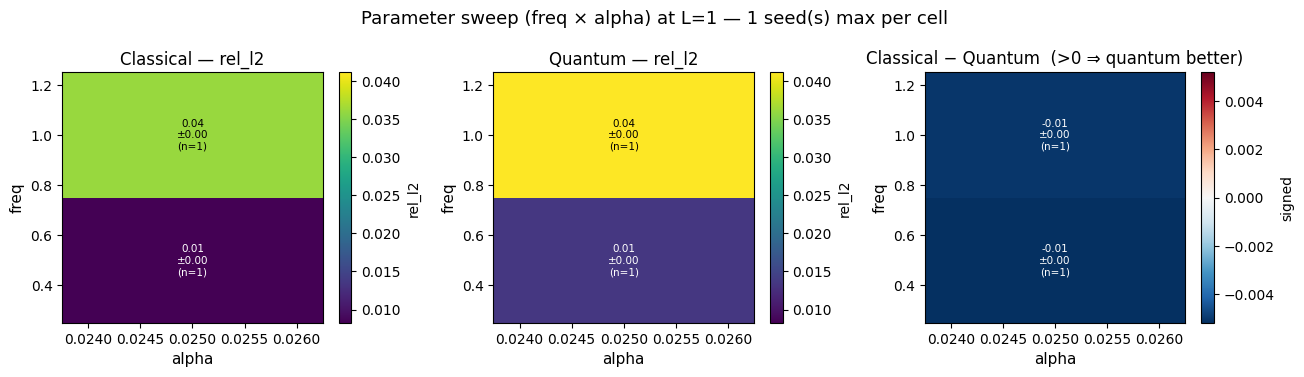

In [11]:
# Plotting only ever reads from disk -- rerun this cell any time (e.g. after
# editing plot_param_sweep_heatmap) without retraining anything.
param_sweep_ckpts = load_checkpoints(PARAM_SWEEP_DIR, pde_type=PDE_TYPE, L=L_PARAM_SWEEP)
print(f"{len(param_sweep_ckpts)} checkpoints loaded")

fig = plot_param_sweep_heatmap(
    param_sweep_ckpts, param1_name="freq", param2_name=PARAM2_NAME,
    metric="rel_l2", save_path=ROOT / "figures" / "checkpoint_pipeline" / "param_sweep_heatmap.png",
)


In [9]:
# Quick table view of every run in this experiment -- sort/filter as needed.
checkpoints_to_dataframe(param_sweep_ckpts).sort_values(["freq", PARAM2_NAME, "model_type", "seed"])


,schema_version,pde_type,model_type,L,feature_size,hidden_feature,hidden_readout,quantum_output_size,seed,epochs,...,alpha,rel_l2,mae,max_abs_error,rmse,eval_epoch,param_count,analytic_bound,diag_passed,path
0,1,heat,classical,1,4,16,18,6.0,42,600,...,0.025,0.008270,0.004057,0.015422,0.005153,600,310,NaN,True,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
1,1,heat,quantum,1,4,16,4,NaN,42,600,...,0.025,0.013442,0.006860,0.019104,0.008375,600,310,3.0,True,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
2,1,heat,classical,1,4,16,18,6.0,42,600,...,0.025,0.036072,0.012568,0.060106,0.016749,600,310,NaN,True,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
3,1,heat,quantum,1,4,16,4,NaN,42,600,...,0.025,0.041110,0.014036,0.080687,0.019088,600,310,3.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...


---
## Experiment 2 — L sweep at fixed PDE parameters

Fix `(freq, alpha)`/`(freq, c)`, sweep architecture size `L`, classical vs.
quantum, for every seed in `SEEDS`.

In [ ]:
DEPTHS = [1, 2, 3]

FIXED_FREQ = 2.5
FIXED_ALPHA_OR_C = 0.025

if PDE_TYPE == "heat":
    L_SWEEP_PDE = HeatEquation(freq=FIXED_FREQ, alpha=FIXED_ALPHA_OR_C)
else:
    L_SWEEP_PDE = WaveEquation(freq=FIXED_FREQ, c=FIXED_ALPHA_OR_C)

L_SWEEP_DIR = ROOT / "checkpoints" / "L_sweep"


In [13]:
run_L_sweep_checkpoints(
    ckpt_dir=L_SWEEP_DIR,
    pde=L_SWEEP_PDE,
    depths=DEPTHS,
    feature_size=FEATURE_SIZE, hidden_feature=HIDDEN_FEATURE,
    hidden_readout_quantum=HIDDEN_READOUT_QUANTUM,
    seeds=SEEDS, epochs=EPOCHS, device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
    match_cache=MATCH_CACHE,
)


[checkpoints] L=1: quantum_params=310  bound=±3  classical match -> quantum_output_size=6 hidden_readout=18 params=310 (diff=+0)
Parameters — total: 310  trainable: 310

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 2.3907e+00 | PDE: 3.65e-04 | Cons: 3.10e-02 | IC: 4.75e-01 | BC: 0.00e+00 | Time: 0.1s
Evaluating on 60×60 grid …
  Relative L2 : 1.0052e+00
  MAE         : 1.1197e-01
  Max abs err : 1.0206e+00
  RMSE        : 2.0949e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0024e+00
  MAE         : 1.0841e-01
  Max abs err : 1.0100e+00
  RMSE        : 2.0890e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0003e+00
  MAE         : 1.0531e-01
  Max abs err : 1.0084e+00
  RMSE        : 2.0845e-01
Evaluating on 60×60 grid …
  Relative L2 : 1.0009e+00
  MAE         : 1.0644e-01
  Max abs err : 1.0112e+00
  RMSE        : 2.0858e-01

Done — 1.4s total
[track_best] restoring epoch 400/600 weights (fixed-grid rel_l2=1.0003e+00) in place of the final epoch's 

[PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L1__fs4_hf16_hr18_qos6__classical__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L1__fs4_hf16_hr4__quantum__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L2__fs4_hf16_hr54_qos2__classical__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L2__fs4_hf16_hr4__quantum__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L3__fs4_hf16_hr59_qos3__classical__seed42__ep600.pt'),
 PosixPath('/Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L3__fs4_hf16_hr4__quantum__seed42__ep600.pt')]

6 checkpoints loaded
Saved: /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/figures/checkpoint_pipeline/L_sweep.png


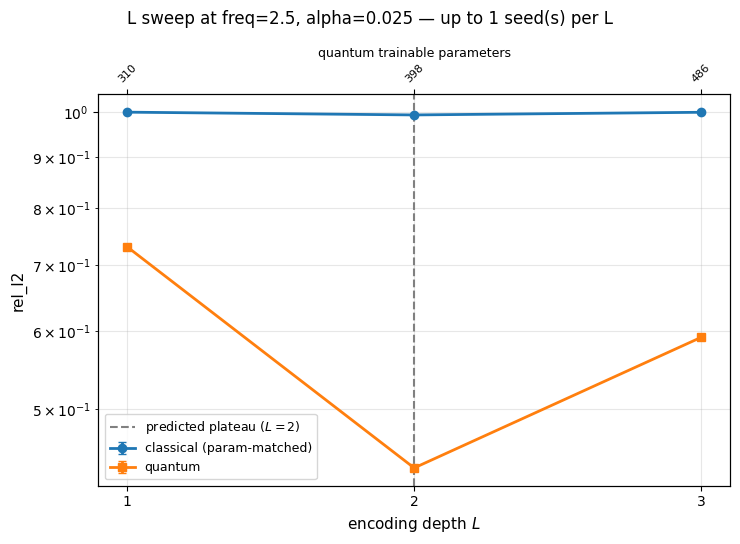

In [14]:
L_sweep_ckpts = load_checkpoints(
    L_SWEEP_DIR, pde_type=PDE_TYPE, freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)
print(f"{len(L_sweep_ckpts)} checkpoints loaded")

# target_frequency: the PDE's integer spatial mode (2*freq for the heat
# convention used elsewhere in this repo) -- marks the theory's predicted
# plateau point (L * n_photons >= target_frequency).
fig = plot_L_sweep(
    L_sweep_ckpts, metric="rel_l2", target_frequency=2 * FIXED_FREQ,
    save_path=ROOT / "figures" / "checkpoint_pipeline" / "L_sweep.png",
)


In [15]:
checkpoints_to_dataframe(L_sweep_ckpts).sort_values(["L", "model_type", "seed"])


,schema_version,pde_type,model_type,L,feature_size,hidden_feature,hidden_readout,quantum_output_size,seed,epochs,...,alpha,rel_l2,mae,max_abs_error,rmse,eval_epoch,param_count,analytic_bound,diag_passed,path
0,1,heat,classical,1,4,16,18,6.0,42,600,...,0.025,1.000275,0.105311,1.008384,0.208453,400,310,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
1,1,heat,quantum,1,4,16,4,NaN,42,600,...,0.025,0.730332,0.088587,0.785892,0.152198,200,310,3.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
3,1,heat,classical,2,4,16,54,2.0,42,600,...,0.025,0.993817,0.123673,1.049606,0.207107,600,398,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
2,1,heat,quantum,2,4,16,4,NaN,42,600,...,0.025,0.435439,0.054787,0.522685,0.090743,600,398,6.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
5,1,heat,classical,3,4,16,59,3.0,42,600,...,0.025,1.000013,0.105013,1.002126,0.208398,400,487,NaN,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...
4,1,heat,quantum,3,4,16,4,NaN,42,600,...,0.025,0.591000,0.076877,0.629444,0.123161,600,486,9.0,False,/Users/honore/Desktop/code_QPINN_jad/QPINN-Ana...


---
## Per-checkpoint plots — training curve, spectral content, learnt vs. exact solution

Pick any single run from either experiment above (by its row in the
dataframe / its config) and inspect it directly, with no retraining. Spectral
content only applies to `model_type="quantum"` checkpoints (classical models
have no quantum layer).

In [16]:
# Example: the quantum run with the largest error in the L sweep -- swap in
# any (dir, filters) you want to look at.
df = checkpoints_to_dataframe(L_sweep_ckpts)
worst = df[df.model_type == "quantum"].sort_values("rel_l2", ascending=False).iloc[0]
print(worst)

ckpt = load_checkpoints(
    L_SWEEP_DIR, model_type="quantum", L=int(worst.L), seed=int(worst.seed),
    freq=FIXED_FREQ, **{PARAM2_NAME: FIXED_ALPHA_OR_C},
)[0]


schema_version                                                         1
pde_type                                                            heat
model_type                                                       quantum
L                                                                      1
feature_size                                                           4
hidden_feature                                                        16
hidden_readout                                                         4
quantum_output_size                                                  NaN
seed                                                                  42
epochs                                                               600
track_best                                                          True
eval_every                                                           200
eval_nx                                                               60
eval_nt                                            

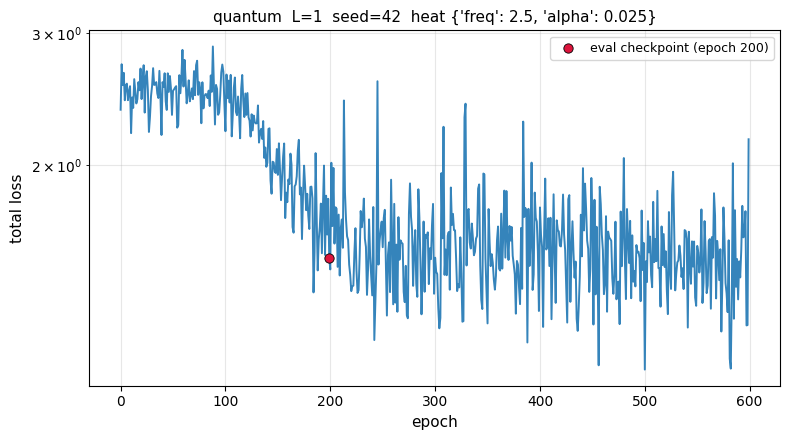

In [17]:
_ = plot_checkpoint_training_curve(ckpt, component="total")


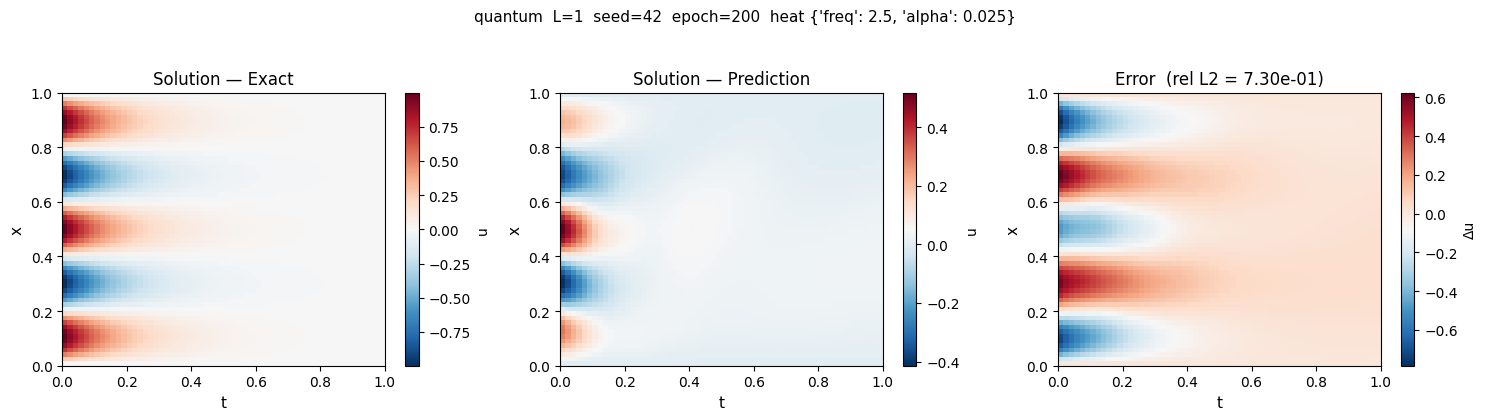

In [21]:
_ = plot_checkpoint_solution(ckpt)


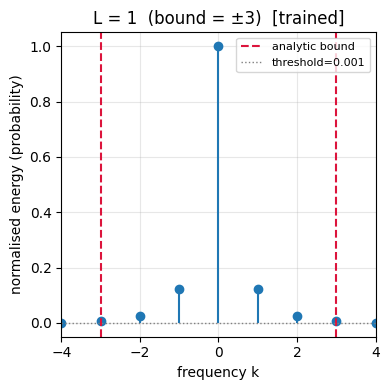

In [22]:
_ = plot_checkpoint_spectrum(ckpt)  # quantum-only


---

## Resuming — continue training an existing checkpoint

`resume_checkpoint` takes any checkpoint (a loaded dict or a path), trains
it for a few hundred more epochs, and saves the result as a NEW file (same
config, `epochs` bumped, plus a `resumed_from_epochs` field) — the original
file is untouched. This is a lightweight resume (fresh optimizer state,
reseeded sampling for the extra epochs), not bit-exact continuation; see
`resume_checkpoint`'s docstring for why that's fine here.

Sanity-checking it on the `ckpt` picked out above: rel_l2 should improve (or
at least not get meaningfully worse), the epoch count should grow by exactly
`additional_epochs`, and the training curve should show the original run's
history followed seamlessly by the new epochs, with a marker at the
combined run's actual eval checkpoint.

In [24]:
print(f"before resume: epochs={ckpt['config']['epochs']}  rel_l2={ckpt['metrics']['rel_l2']:.3e}")

resumed_path = resume_checkpoint(
    ckpt_dir=L_SWEEP_DIR,
    source=ckpt,
    additional_epochs=200,
    device=DEVICE,
    track_best=TRACK_BEST, eval_every=EVAL_EVERY,
)
resumed_ckpt = load_checkpoint(resumed_path)

print(f"after resume:  epochs={resumed_ckpt['config']['epochs']}  rel_l2={resumed_ckpt['metrics']['rel_l2']:.3e}")
assert resumed_ckpt["config"]["epochs"] == ckpt["config"]["epochs"] + 200
assert len(resumed_ckpt["history"]) == len(ckpt["history"]) + 200
print("OK -- resumed checkpoint has the expected epoch count and history length")


before resume: epochs=600  rel_l2=7.303e-01
Parameters — total: 310  trainable: 310

Training for 200 epochs on cpu  (dtype=torch.float32)
Epoch     1/200 | Loss: 1.6474e+00 | PDE: 7.99e-02 | Cons: 1.12e+00 | IC: 2.02e-01 | BC: 0.00e+00 | Time: 0.1s
Evaluating on 60×60 grid …
  Relative L2 : 8.0648e-01
  MAE         : 9.2906e-02
  Max abs err : 7.6553e-01
  RMSE        : 1.6807e-01
Evaluating on 60×60 grid …
  Relative L2 : 7.3128e-01
  MAE         : 8.4580e-02
  Max abs err : 6.9447e-01
  RMSE        : 1.5239e-01

Done — 18.6s total
[track_best] restoring epoch 200/200 weights (fixed-grid rel_l2=7.3128e-01) in place of the final epoch's weights (final-epoch fixed-grid rel_l2=7.3128e-01)
Evaluating on 60×60 grid …
  Relative L2 : 7.3128e-01
  MAE         : 8.4580e-02
  Max abs err : 6.9447e-01
  RMSE        : 1.5239e-01
[checkpoints] resumed /Users/honore/Desktop/code_QPINN_jad/QPINN-Analysis/checkpoints/L_sweep/heat__alpha0p025_freq2p5__L1__fs4_hf16_hr4__quantum__seed42__ep600.pt (600